In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import tensorflow as tf
import numpy as np
import time
import matplotlib.pyplot as plt
import os # For creating directories
import random # For image buffer
import shutil # For zipping files
from PIL import Image # For saving images more efficiently
import pathlib

tf.config.run_functions_eagerly(True)


#import os
#for dirname, _, filenames in os.walk('/kaggle/input'):
#    for filename in filenames:
#        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

2025-09-11 23:42:02.462289: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1757634122.658806      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1757634122.712998      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


# 1. Project Overview & Generative Models
This project explores the fascinating field of generative deep learning by **transforming real photographs into the style of Monet's paintings**. We will use two distinct datasets—one of Monet's paintings and another of real-world photographs—to teach the model to capture the characteristic brushstrokes, colors, and ethereal atmosphere of Impressionism without the need for paired image examples.

**The Problem: Unpaired Image Style Transfer**

The goal is to convert a regular photograph into the style of a Claude Monet painting. The key challenge is that we have a collection of photographs and a separate collection of Monet paintings, but there is no direct one-to-one correspondence between them. We don't have a photo of a specific landscape and a Monet painting of that exact same scene. Therefore, it is a unpaired image style transer problem.

**The Solution: The CycleGAN Framework**

To solve this problem, we need an architecture that can learn a translation between two domains without paired examples. The CycleGAN framework is the ideal solution for this. ( Reference: [Jun-Yan Zhu, Taesung Park, Phillip Isola, and Alexei A. Efros. "Unpaired Image-to-Image Translation using Cycle-Consistent Adversarial Networks." arXiv preprint arXiv:1703.10593, 2017.](https://arxiv.org/abs/1703.10593) )

It works by training two generators simultaneously: one to convert photos to the Monet style, and another to convert Monet paintings back to photos.

**Loss Function**

The genius of CycleGAN lies in its cycle-consistency loss. This loss function forces the model to be reversible. For example, a photo converted to a Monet painting and then back to a photo must be nearly identical to the original photo. This mechanism prevents the model from generating random or meaningless images and ensures it learns a genuine style transfer while preserving the original image's content.


# 2. Exploratory Data Analysis (EDA)

In [2]:
# Load the images
def load_image_original(path):
    img = Image.open(path).convert("RGB")  # keep original size
    arr = np.array(img)  # shape: (H, W, 3)
    return arr

# Point to the dataset directory
monet_dir = pathlib.Path("/kaggle/input/gan-getting-started/monet_jpg")
photo_dir = pathlib.Path("/kaggle/input/gan-getting-started/photo_jpg")

# Collect all image file paths
monet_jpg_paths = list(monet_dir.glob("*.jpg"))
photo_jpg_paths = list(photo_dir.glob("*.jpg"))


## 2.1 The samples of images

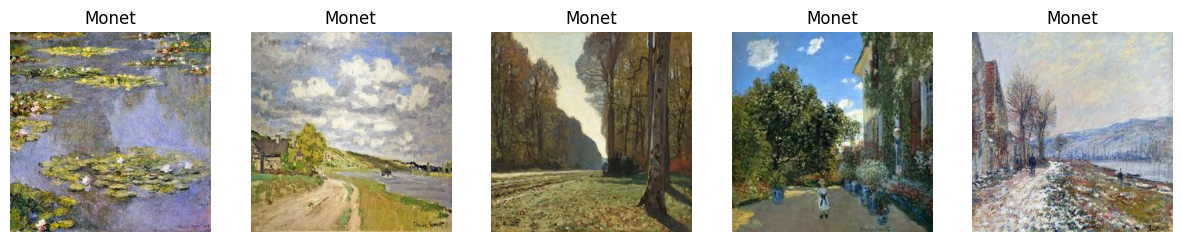

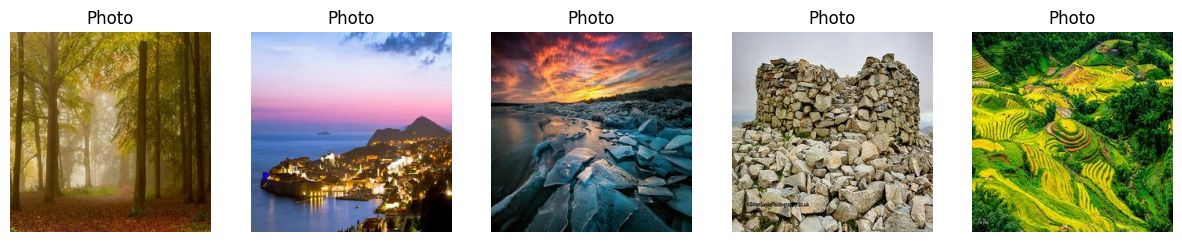

In [3]:
def show_sample_images(images, label):
    plt.figure(figsize=(15,3))
    for i, img in enumerate(images):
        plt.subplot(1, len(images), i+1)
        plt.imshow(img)  # scale back to [0,1] for display
        plt.axis('off')
        plt.title(label)
    plt.show()
    
monet_imgs =[load_image_original(p) for p in monet_jpg_paths[:5]]
photo_imgs = [load_image_original(p) for p in photo_jpg_paths[:5]]

show_sample_images(monet_imgs, "Monet")
show_sample_images(photo_imgs, "Photo")

## 2.2 The number of images

In [4]:
num_monet = len(monet_jpg_paths)
num_photo = len(photo_jpg_paths)

print(f'We have {num_monet} drawings and {num_photo} photos.')

We have 300 drawings and 7038 photos.


## 2.3 The shapes of images

In [5]:
monet_imgs_raw = [load_image_original(p) for p in monet_jpg_paths[:]]
photo_imgs_raw = [load_image_original(p) for p in photo_jpg_paths[:]]

# Function to check shapes of all images in a list
def check_shapes(image_list, name="Dataset"):
    shapes = [img.shape for img in image_list]
    unique_shapes = set(shapes)
    print(f"--- {name} Image Shapes ---")
    if len(unique_shapes) == 1:
        print(f"All images have the same shape: {unique_shapes.pop()}")
    else:
        print("Images have varying shapes:")
        for shape in unique_shapes:
            print(shape)
    print(f"Total images checked: {len(image_list)}\n")

# Check Monet images
check_shapes(monet_imgs_raw, "Monet")

# Check Photo images
check_shapes(photo_imgs_raw, "Photo")


--- Monet Image Shapes ---
All images have the same shape: (256, 256, 3)
Total images checked: 300

--- Photo Image Shapes ---
All images have the same shape: (256, 256, 3)
Total images checked: 7038



## 2.4 Compare the Pixel Intensity Between Monet and Photo

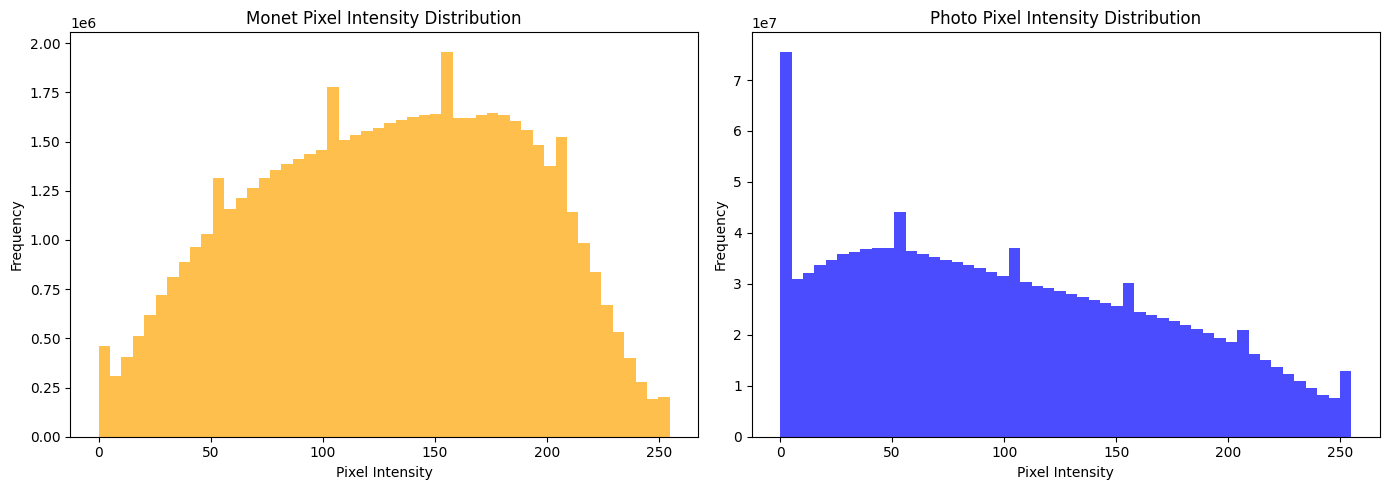

In [6]:
# Function to load raw image pixels
def load_image_raw(path):
    img = Image.open(path).convert("RGB")
    return np.array(img)  # keep in [0,255]

# Collect all images
monet_images = [load_image_raw(path) for path in monet_dir.glob("*.jpg")]
photo_images = [load_image_raw(path) for path in photo_dir.glob("*.jpg")]

# Flatten pixels and combine
monet_pixels = np.concatenate([img.flatten() for img in monet_images])
photo_pixels = np.concatenate([img.flatten() for img in photo_images])

# Create subplots: 1 row, 2 columns
fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Monet histogram
axes[0].hist(monet_pixels, bins=50, color="orange", alpha=0.7)
axes[0].set_title("Monet Pixel Intensity Distribution")
axes[0].set_xlabel("Pixel Intensity")
axes[0].set_ylabel("Frequency")

# Photo histogram
axes[1].hist(photo_pixels, bins=50, color="blue", alpha=0.7)
axes[1].set_title("Photo Pixel Intensity Distribution")
axes[1].set_xlabel("Pixel Intensity")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

**Summary**

| Feature                         | Monet Paintings                                                                                                           | Photos                                                                                                                        |
| ------------------------------- | ------------------------------------------------------------------------------------------------------------------------- | ----------------------------------------------------------------------------------------------------------------------------- |
| **Shape of Distribution**       | Relatively smooth, roughly bell-shaped (some peaks at certain intensities), slightly skewed to lower intensities.         | Skewed towards dark (low intensity) pixels; very high spike at 0 (black/near-black pixels); less smooth overall.              |
| **Peaks**                       | Some distinct spikes around certain mid-range intensities (\~50, 100, 150, 200) likely due to color regions in paintings. | Major spike at 0, smaller spikes at \~60, 110, 160, 210 (likely quantization artifacts or common intensity levels in photos). |
| **Spread**                      | Most pixel intensities are between 20–240, fairly evenly distributed.                                                     | Most pixels concentrated at lower intensities, but extends across full 0–255 range.                                           |
| **Frequency Magnitude**         | \~0 to 2×10⁶                                                                                                              | \~0 to 7×10⁷ (photos have many more pixels in total)                                                                          |


---

1. Monet images have a smoother intensity distribution, whereas photos have extreme peaks and more skew.

2. This difference is important for tasks like style transfer or image-to-image translation, because:

3. Neural networks may need normalization to handle the contrast differences.

4. Monet’s smoother histogram might lead to more uniform feature representations, while photos contain more sharp intensity transitions.

# 3. CycleGAN framework

We need the CycleGAN framework because it is designed for a specific type of style transfer problem: one where we don't have a matching pair of images. For example, we don't have a photo of a specific landscape taken by a photographer and the exact same landscape painted by Monet. The CycleGAN framework, as shown in the code, solves this problem with two key innovations.

The Two-Way Generators: As seen in the file, the program uses two generators, G_photo2monet and G_monet2photo. We need this two-way setup for the cyclical training process that comes next.

The Cycle-Consistency Loss: This is the core reason we need CycleGAN. The train_step function shows how it works:

A photo is converted to a fake Monet image.

That fake Monet image is then converted back to a photo.

The cycle_loss then measures the difference between the final image and the original.

This cycle forces the generators to learn a meaningful, reversible mapping between the two domains. It ensures that the model changes only the style while keeping the original content intact, which is exactly what a style transfer program should do without requiring paired datasets.

## 3.1 Model Architecture

In [7]:
def conv_block(inputs, filters, kernel_size, strides, apply_batchnorm=True, activation='leaky_relu'):
    initializer = tf.random_normal_initializer(0., 0.02)
    x = tf.keras.layers.Conv2D(filters, kernel_size, strides=strides, padding='same',
                               kernel_initializer=initializer, use_bias=False)(inputs)
    if apply_batchnorm:
        x = tf.keras.layers.BatchNormalization()(x)
    if activation == 'leaky_relu':
        x = tf.keras.layers.LeakyReLU(alpha=0.2)(x) # Common alpha for LeakyReLU in GANs
    elif activation == 'relu':
        x = tf.keras.layers.ReLU()(x)
    return x

def deconv_block(inputs, filters, kernel_size, strides, apply_batchnorm=True, apply_dropout=False, activation='relu'):
    initializer = tf.random_normal_initializer(0., 0.02)
    x = tf.keras.layers.Conv2DTranspose(filters, kernel_size, strides=strides, padding='same',
                                       kernel_initializer=initializer, use_bias=False)(inputs)
    if apply_batchnorm:
        x = tf.keras.layers.BatchNormalization()(x)
    if apply_dropout:
        x = tf.keras.layers.Dropout(0.5)(x)
    if activation == 'relu':
        x = tf.keras.layers.ReLU()(x)
    return x

def residual_block(inputs, filters, kernel_size=(3, 3), apply_dropout=False):
    # First Conv layer
    x = conv_block(inputs, filters, kernel_size, strides=1, apply_batchnorm=True, activation='relu')

    if apply_dropout:
        x = tf.keras.layers.Dropout(0.5)(x)

    # Second Conv layer (no activation here, activation applied after adding shortcut)
    x = tf.keras.layers.Conv2D(filters, kernel_size, strides=1, padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)

    # Add skip connection
    output = tf.keras.layers.Add()([inputs, x])
    output = tf.keras.layers.ReLU()(output) # Final activation after adding residual
    return output


# --- Enhanced Generator Architecture (U-Net with ResNet-like Bottleneck) ---
def create_generator(num_residual_blocks=9): # Common to use 6 or 9 residual blocks
    inputs = tf.keras.layers.Input(shape=(256, 256, 3))

    # Encoder (Initial Convolution + Downsampling)
    # C7S1-64: Conv-7x7, Stride-1, #filters-64
    x = conv_block(inputs, 64, 7, strides=1, apply_batchnorm=True, activation='relu') # (bs, 256, 256, 64)

    # D128: Downsample to 128x128, #filters-128
    x = conv_block(x, 128, 3, strides=2, apply_batchnorm=True, activation='relu') # (bs, 128, 128, 128)
    # D256: Downsample to 64x64, #filters-256
    x = conv_block(x, 256, 3, strides=2, apply_batchnorm=True, activation='relu') # (bs, 64, 64, 256)

    # Residual Blocks (Bottleneck)
    for _ in range(num_residual_blocks):
        x = residual_block(x, 256) # (bs, 64, 64, 256)

    # Decoder (Upsampling + Final Convolution)
    # U128: Upsample to 128x128, #filters-128
    x = deconv_block(x, 128, 3, strides=2, apply_batchnorm=True, activation='relu') # (bs, 128, 128, 128)
    # U64: Upsample to 256x256, #filters-64
    x = deconv_block(x, 64, 3, strides=2, apply_batchnorm=True, activation='relu') # (bs, 256, 256, 64)

    # C7S1-3: Final Conv-7x7, Stride-1, #filters-3 (output channels)
    initializer = tf.random_normal_initializer(0., 0.02)
    x = tf.keras.layers.Conv2D(3, 7, strides=1, padding='same',
                               kernel_initializer=initializer, activation='tanh')(x) # (bs, 256, 256, 3)

    return tf.keras.Model(inputs=inputs, outputs=x, name='Generator')


# --- Improved Discriminator Architecture (PatchGAN) ---
def create_discriminator():
    initializer = tf.random_normal_initializer(0., 0.02)

    inp = tf.keras.layers.Input(shape=[256, 256, 3], name='input_image')

    # C64: Conv-4x4, Stride-2, #filters-64 (no batchnorm on first layer as per original paper)
    x = conv_block(inp, 64, 4, strides=2, apply_batchnorm=False, activation='leaky_relu') # (bs, 128, 128, 64)
    # C128: Conv-4x4, Stride-2, #filters-128
    x = conv_block(x, 128, 4, strides=2, apply_batchnorm=True, activation='leaky_relu') # (bs, 64, 64, 128)
    # C256: Conv-4x4, Stride-2, #filters-256
    x = conv_block(x, 256, 4, strides=2, apply_batchnorm=True, activation='leaky_relu') # (bs, 32, 32, 256)
    # C512: Conv-4x4, Stride-1, #filters-512
    x = conv_block(x, 512, 4, strides=1, apply_batchnorm=True, activation='leaky_relu') # (bs, 32, 32, 512)

    # Last layer output 1 value per patch (PatchGAN)
    last = tf.keras.layers.Conv2D(1, (4, 4), strides=1, padding='same', kernel_initializer=initializer)(x) # (bs, 32, 32, 1)

    return tf.keras.Model(inputs=inp, outputs=last, name='Discriminator')

# Instantiate improved models
G_monet2photo = create_generator() # Generator for Monet -> Photo
G_photo2monet = create_generator() # Generator for Photo -> Monet
D_photo = create_discriminator()   # Discriminator for Photo domain
D_monet = create_discriminator()   # Discriminator for Monet domain

I0000 00:00:1757634278.249068      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0
/usr/local/lib/python3.11/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


## 3.2 Loss function

In [8]:
# Loss for Generator's Adversarial Loss
def generator_loss(fake_output):
    return tf.reduce_mean(tf.keras.losses.binary_crossentropy(tf.ones_like(fake_output), fake_output, from_logits=True))

# Loss for Cycle Consistency (L1 Loss)
LAMBDA_CYCLE = 10.0
def cycle_loss(real_image, cycled_image):
    loss = tf.reduce_mean(tf.abs(real_image - cycled_image))
    return LAMBDA_CYCLE * loss

# Loss for Identity Mapping (L1 Loss)
LAMBDA_IDENTITY = 0.5 * LAMBDA_CYCLE
def identity_loss(real_image, same_image):
    loss = tf.reduce_mean(tf.abs(real_image - same_image))
    return LAMBDA_IDENTITY * loss

# Loss for Discriminator
def discriminator_loss(real_output, fake_output):
    real_loss = tf.reduce_mean(tf.keras.losses.binary_crossentropy(tf.ones_like(real_output), real_output, from_logits=True))
    fake_loss = tf.reduce_mean(tf.keras.losses.binary_crossentropy(tf.zeros_like(fake_output), fake_output, from_logits=True))
    total_loss = real_loss + fake_loss
    return total_loss * 0.5

In [9]:
# --- Optimizers with Gradient Clipping and Learning Rate Decay ---
# Initial learning rate
initial_learning_rate = 2e-4

# Decay for 100 epochs, assuming 300 steps/epoch, roughly 30000 steps total.
# Let's decay over the whole training process for fine-tuning.
total_training_steps = 1 * 3 # EPOCHS * steps_per_epoch
decay_steps = int(total_training_steps * 0.5) # Start decaying after half the training
decay_rate = 0.9 # Adjusted decay rate

lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate,
    decay_steps=decay_steps,
    decay_rate=decay_rate,
    staircase=True # Decays in discrete steps, useful for batch training
)

gen_optimizer = tf.keras.optimizers.Adam(lr_schedule, beta_1=0.5, clipnorm=1.0)
disc_optimizer = tf.keras.optimizers.Adam(lr_schedule, beta_1=0.5, clipnorm=1.0)


# --- Image Buffer for Discriminator Training ---
class ImageBuffer:
    def __init__(self, buffer_max_size=50):
        self.buffer_max_size = buffer_max_size
        self.images = []

    def __call__(self, new_images):
        if self.buffer_max_size == 0:
            return new_images
        return_images = []
        for image in new_images: # Assuming new_images is a batch
            image = tf.expand_dims(image, axis=0) # Add batch dimension back for single image
            if len(self.images) < self.buffer_max_size:
                self.images.append(image)
                return_images.append(image)
            else:
                p = random.uniform(0, 1)
                if p > 0.5:
                    # Randomly take an image from the buffer and replace it
                    random_index = random.randrange(len(self.images))
                    return_images.append(self.images[random_index])
                    self.images[random_index] = image
                else:
                    # Keep the new image and do not add to buffer
                    return_images.append(image)
        return tf.concat(return_images, axis=0) # Concatenate back to a batch


# Instantiate image buffers
fake_monet_buffer = ImageBuffer(buffer_max_size=50)
fake_photo_buffer = ImageBuffer(buffer_max_size=50)



## 3.3 Training Step

/usr/local/lib/python3.11/dist-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


Displaying 3 initial Monet and Photo samples before training...


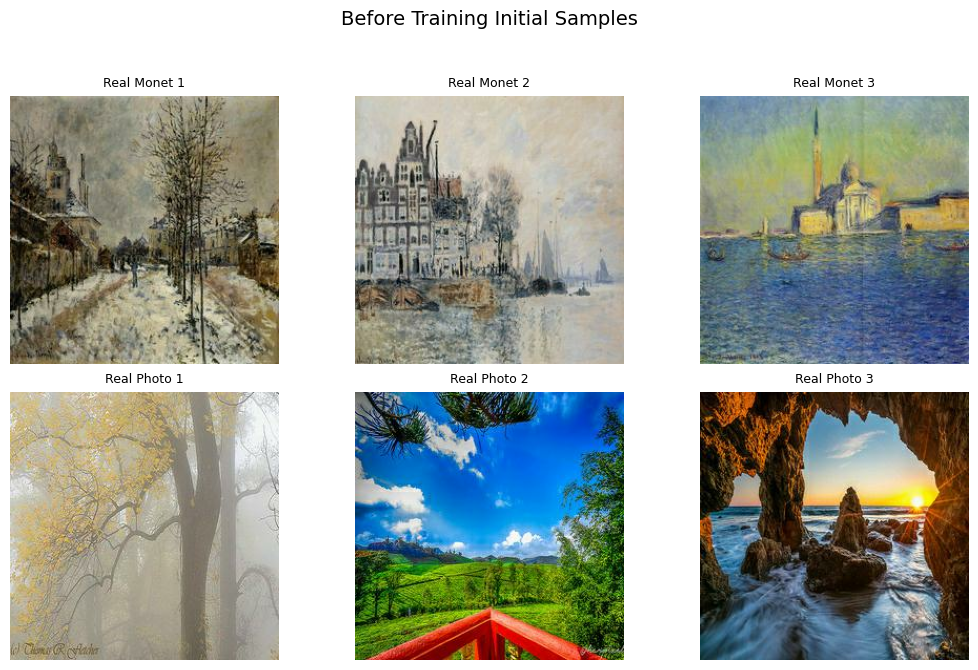

Starting training loop with 10 epochs and 300 steps per epoch...


I0000 00:00:1757634283.534139      19 cuda_dnn.cc:529] Loaded cuDNN version 90300


Epoch 1/10, Step 1/300: Training...
Epoch 1/10, Step 51/300: Training...
Epoch 1/10, Step 101/300: Training...
Epoch 1/10, Step 151/300: Training...
Epoch 1/10, Step 201/300: Training...
Epoch 1/10, Step 251/300: Training...
Epoch 1/10 done in 762.96s
Epoch 2/10, Step 1/300: Training...
Epoch 2/10, Step 51/300: Training...
Epoch 2/10, Step 101/300: Training...
Epoch 2/10, Step 151/300: Training...
Epoch 2/10, Step 201/300: Training...
Epoch 2/10, Step 251/300: Training...
Epoch 2/10 done in 748.22s
Epoch 3/10, Step 1/300: Training...
Epoch 3/10, Step 51/300: Training...
Epoch 3/10, Step 101/300: Training...
Epoch 3/10, Step 151/300: Training...
Epoch 3/10, Step 201/300: Training...
Epoch 3/10, Step 251/300: Training...
Epoch 3/10 done in 752.66s
Epoch 4/10, Step 1/300: Training...
Epoch 4/10, Step 51/300: Training...
Epoch 4/10, Step 101/300: Training...
Epoch 4/10, Step 151/300: Training...
Epoch 4/10, Step 201/300: Training...
Epoch 4/10, Step 251/300: Training...
Epoch 4/10 done in 

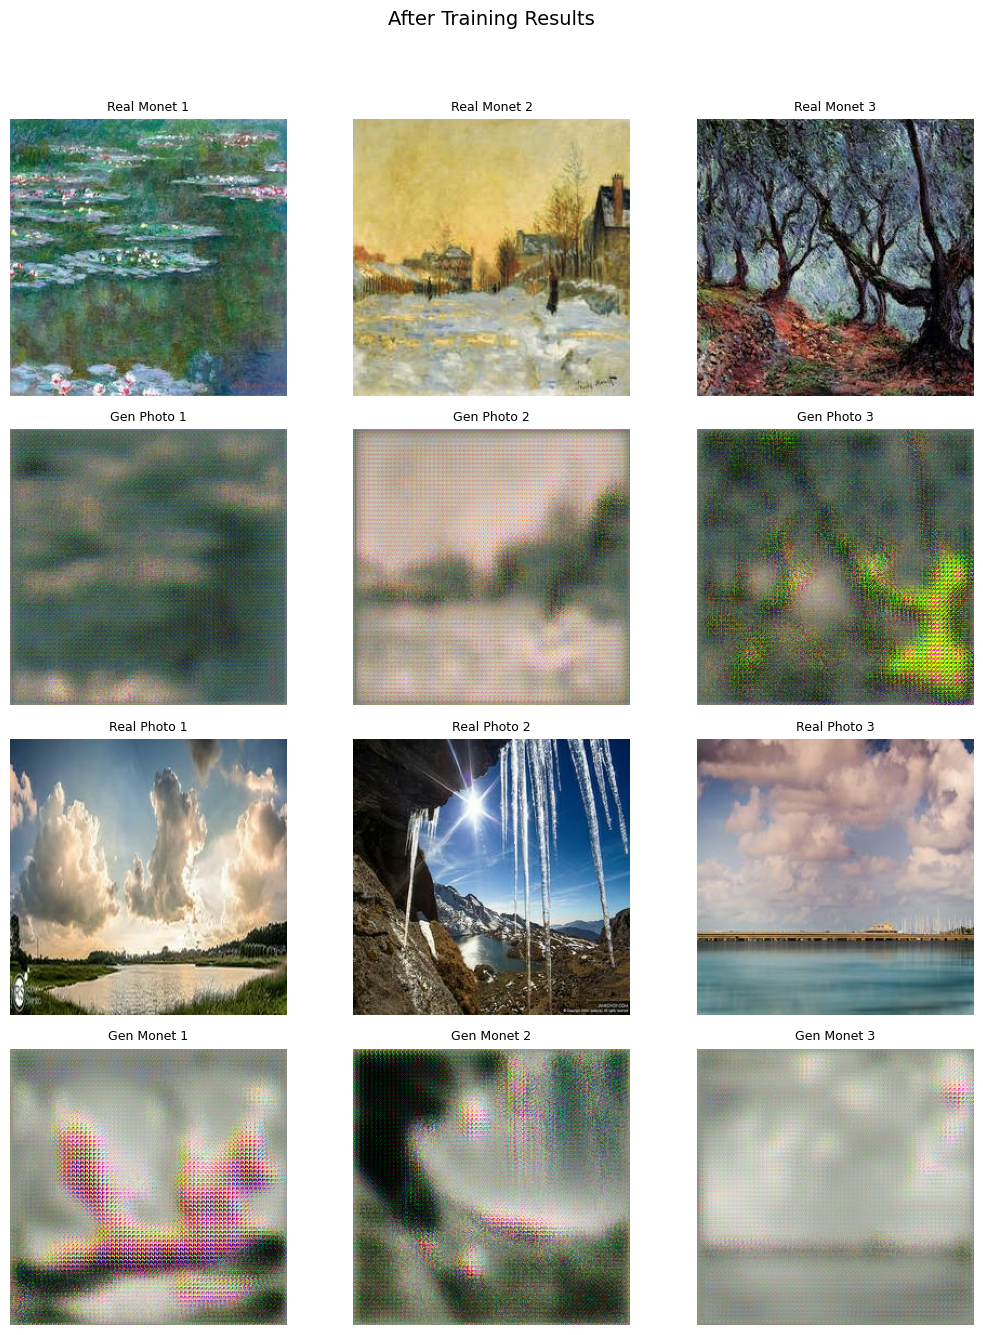

Now proceeding to generate and zip the 8,000 Monet-style images...
Generating 8000 Monet-style images...
Generated 1000/8000 images...
Generated 2000/8000 images...
Generated 3000/8000 images...
Generated 4000/8000 images...
Generated 5000/8000 images...
Generated 6000/8000 images...
Generated 7000/8000 images...
Generated 8000/8000 images...
Finished generating 8000 images in 511.63s.


In [10]:
# --- Train Step Function ---
@tf.function
def train_step(real_monet, real_photo):
    with tf.GradientTape(persistent=True) as tape:
        # Generate fake images
        fake_photo = G_monet2photo(real_monet, training=True)
        fake_monet = G_photo2monet(real_photo, training=True)

        # Cycle images
        cycled_monet = G_photo2monet(fake_photo, training=True)
        cycled_photo = G_monet2photo(fake_monet, training=True)

        # Identity images
        same_photo = G_monet2photo(real_photo, training=True)
        same_monet = G_photo2monet(real_monet, training=True)

        # Get images from buffer for discriminator training
        buffered_fake_monet = fake_monet_buffer(fake_monet)
        buffered_fake_photo = fake_photo_buffer(fake_photo)

        # Discriminator predictions
        disc_real_monet = D_monet(real_monet, training=True)
        disc_fake_monet = D_monet(buffered_fake_monet, training=True) # Use buffered fakes

        disc_real_photo = D_photo(real_photo, training=True)
        disc_fake_photo = D_photo(buffered_fake_photo, training=True) # Use buffered fakes

        # Generator losses
        gen_monet2photo_loss = generator_loss(disc_fake_photo)
        gen_photo2monet_loss = generator_loss(disc_fake_monet)

        total_cycle_loss = cycle_loss(real_monet, cycled_monet) + cycle_loss(real_photo, cycled_photo)

        total_gen_monet2photo_loss = gen_monet2photo_loss + total_cycle_loss + identity_loss(real_photo, same_photo)
        total_gen_photo2monet_loss = gen_photo2monet_loss + total_cycle_loss + identity_loss(real_monet, same_monet)

        total_generator_loss = total_gen_monet2photo_loss + total_gen_photo2monet_loss

        # Discriminator losses
        disc_monet_loss = discriminator_loss(disc_real_monet, disc_fake_monet)
        disc_photo_loss = discriminator_loss(disc_real_photo, disc_fake_photo)

        total_discriminator_loss = disc_monet_loss + disc_photo_loss


    # Calculate gradients for generators
    generator_trainable_variables = G_monet2photo.trainable_variables + G_photo2monet.trainable_variables
    generator_gradients = tape.gradient(total_generator_loss, generator_trainable_variables)

    # Calculate gradients for discriminators
    discriminator_trainable_variables = D_monet.trainable_variables + D_photo.trainable_variables
    discriminator_gradients = tape.gradient(total_discriminator_loss, discriminator_trainable_variables)

    # Apply gradients
    gen_optimizer.apply_gradients(zip(generator_gradients, generator_trainable_variables))
    disc_optimizer.apply_gradients(zip(discriminator_gradients, discriminator_trainable_variables))

    return fake_photo, fake_monet # Return generated images for saving/display


# --- Helper function to display images (adapted to show real images) ---
def display_samples(monet_samples, photo_samples, title_prefix=""):
    num_samples_to_show = len(monet_samples) # Should be 3
    if num_samples_to_show == 0:
        print("No samples to display.")
        return

    fig, axes = plt.subplots(2, num_samples_to_show, figsize=(num_samples_to_show * 3.5, 7))

    if num_samples_to_show == 1: # Handle case for single sample
        axes = np.expand_dims(axes, axis=1)

    for i in range(num_samples_to_show):
        real_monet_display = (monet_samples[i][0].numpy() * 0.5 + 0.5) # Denormalize
        real_photo_display = (photo_samples[i][0].numpy() * 0.5 + 0.5) # Denormalize

        axes[0, i].imshow(real_monet_display)
        axes[0, i].set_title(f"Real Monet {i+1}", fontsize=9)
        axes[0, i].axis('off')

        axes[1, i].imshow(real_photo_display)
        axes[1, i].set_title(f"Real Photo {i+1}", fontsize=9)
        axes[1, i].axis('off')

    plt.suptitle(f"{title_prefix} Initial Samples", fontsize=14)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


# --- Helper function to display generated images during training ---
def display_generated_samples(sample_list, num_samples_to_show=3, title_prefix=""):
    if not sample_list:
        print("No samples to display.")
        return

    display_count = min(len(sample_list), num_samples_to_show)
    fig, axes = plt.subplots(4, display_count, figsize=(display_count * 3.5, 14))

    if display_count == 1:
        axes = np.expand_dims(axes, axis=1)

    for i in range(display_count):
        real_monet, real_photo, fake_photo, fake_monet = sample_list[i]

        real_monet_display = (real_monet[0].numpy() * 0.5 + 0.5)
        fake_photo_display = (fake_photo[0].numpy() * 0.5 + 0.5)
        real_photo_display = (real_photo[0].numpy() * 0.5 + 0.5)
        fake_monet_display = (fake_monet[0].numpy() * 0.5 + 0.5)

        axes[0, i].imshow(real_monet_display)
        axes[0, i].set_title(f"Real Monet {i+1}", fontsize=9)
        axes[0, i].axis('off')

        axes[1, i].imshow(fake_photo_display)
        axes[1, i].set_title(f"Gen Photo {i+1}", fontsize=9)
        axes[1, i].axis('off')

        axes[2, i].imshow(real_photo_display)
        axes[2, i].set_title(f"Real Photo {i+1}", fontsize=9)
        axes[2, i].axis('off')

        axes[3, i].imshow(fake_monet_display)
        axes[3, i].set_title(f"Gen Monet {i+1}", fontsize=9)
        axes[3, i].axis('off')

    plt.suptitle(f"{title_prefix} Results", fontsize=14) # Changed title for clarity
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


# --- Dataset Loading and Preprocessing ---
IMG_WIDTH = 256
IMG_HEIGHT = 256
BATCH_SIZE = 1 # Keep batch size 1 for CycleGAN

def preprocess_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_HEIGHT, IMG_WIDTH])
    image = tf.cast(image, tf.float32)
    image = (image / 127.5) - 1 # Normalize to [-1, 1]
    return image

# Dataset directories
MONET_TRAIN_FILEPATH = '/kaggle/input/gan-getting-started/monet_jpg'
PHOTO_TRAIN_FILEPATH = '/kaggle/input/gan-getting-started/photo_jpg'

# Create tf.data.Dataset for Monet and Photo images
# Datasets for initial display and final evaluation (non-repeating, small)
monet_initial_eval_dataset = tf.data.Dataset.list_files(MONET_TRAIN_FILEPATH + '/*.jpg', shuffle=True).take(3) # Take 3 for initial/final display
monet_initial_eval_dataset = monet_initial_eval_dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
monet_initial_eval_dataset = monet_initial_eval_dataset.batch(BATCH_SIZE)

photo_initial_eval_dataset = tf.data.Dataset.list_files(PHOTO_TRAIN_FILEPATH + '/*.jpg', shuffle=True).take(3) # Take 3 for initial/final display
photo_initial_eval_dataset = photo_initial_eval_dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
photo_initial_eval_dataset = photo_initial_eval_dataset.batch(BATCH_SIZE)

# Training datasets (repeating, full)
monet_train_dataset = tf.data.Dataset.list_files(MONET_TRAIN_FILEPATH + '/*.jpg', shuffle=True)
monet_train_dataset = monet_train_dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
monet_train_dataset = monet_train_dataset.batch(BATCH_SIZE).repeat().prefetch(tf.data.AUTOTUNE)

photo_train_dataset = tf.data.Dataset.list_files(PHOTO_TRAIN_FILEPATH + '/*.jpg', shuffle=True)
photo_train_dataset = photo_train_dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
photo_train_dataset = photo_train_dataset.batch(BATCH_SIZE).repeat().prefetch(tf.data.AUTOTUNE)


monet_train_iter = iter(monet_train_dataset)
photo_train_iter = iter(photo_train_dataset)

# --- Parameters for Training and Final Generation ---
EPOCHS = 10 # Further increased epochs for more learning
steps_per_epoch = 300 # Further increased steps per epoch for more training simulation
NUM_OUTPUT_IMAGES = 8000 # Target 8,000 Monet-style images for output
samples_to_display_count = 3 # Number of samples to collect and display at once

# --- Display initial samples before training starts ---
print(f"Displaying {samples_to_display_count} initial Monet and Photo samples before training...")
initial_monet_samples = list(monet_initial_eval_dataset)
initial_photo_samples = list(photo_initial_eval_dataset)
display_samples(initial_monet_samples, initial_photo_samples, title_prefix="Before Training")


print(f"Starting training loop with {EPOCHS} epochs and {steps_per_epoch} steps per epoch...")
for epoch in range(EPOCHS):
    start = time.time()
    for step in range(steps_per_epoch):
        real_monet_batch = next(monet_train_iter)
        real_photo_batch = next(photo_train_iter)

        # We do not need the returned fake images during intermediate training
        _, _ = train_step(real_monet_batch, real_photo_batch)

        if step % 50 == 0:
            print(f"Epoch {epoch+1}/{EPOCHS}, Step {step+1}/{steps_per_epoch}: Training...")

    print(f'Epoch {epoch+1}/{EPOCHS} done in {time.time()-start:.2f}s')

print("Training simulation complete. Displaying final generated results before zipping...")

# --- Display final generated samples after the whole training process ---
final_generated_samples = []
for i in range(samples_to_display_count):
    # Fetch fresh real images for final evaluation from the evaluation dataset
    real_monet_eval = next(iter(monet_initial_eval_dataset.skip(i).take(1)))
    real_photo_eval = next(iter(photo_initial_eval_dataset.skip(i).take(1)))

    # Generate fake images using the final state of the generators (inference mode)
    fake_photo_final = G_monet2photo(real_monet_eval, training=False)
    fake_monet_final = G_photo2monet(real_photo_eval, training=False)

    final_generated_samples.append((real_monet_eval, real_photo_eval, fake_photo_final, fake_monet_final))

# Display the collected final samples
display_generated_samples(final_generated_samples, samples_to_display_count, title_prefix="After Training")

print("Now proceeding to generate and zip the 8,000 Monet-style images...")

# --- Generate and Zip Final Monet-style Images ---
output_dir = '/tmp/monet_output'
os.makedirs(output_dir, exist_ok=True) # Create temporary directory

# Prepare a dataset for generating output images.
output_photo_dataset = tf.data.Dataset.list_files(PHOTO_TRAIN_FILEPATH + '/*.jpg', shuffle=True)
output_photo_dataset = output_photo_dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
output_photo_dataset = output_photo_dataset.batch(1) # Generate one by one
output_photo_iter = iter(output_photo_dataset.repeat()) # Repeat to ensure enough images

generated_count = 0
start_generation_time = time.time()

print(f"Generating {NUM_OUTPUT_IMAGES} Monet-style images...")
while generated_count < NUM_OUTPUT_IMAGES:
    try:
        real_photo_batch = next(output_photo_iter)
    except tf.errors.OutOfRangeError:
        print("Reached end of photo dataset, re-shuffling and restarting iterator.")
        output_photo_dataset = tf.data.Dataset.list_files(PHOTO_TRAIN_FILEPATH + '/*.jpg', shuffle=True)
        output_photo_dataset = output_photo_dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
        output_photo_dataset = output_photo_dataset.batch(1)
        output_photo_iter = iter(output_photo_dataset.repeat()) # Recreate and repeat
        real_photo_batch = next(output_photo_iter) # Get the first element after restart

    # Generate a Monet-style image from a real photo using the trained generator
    generated_monet_image = G_photo2monet(real_photo_batch, training=False)[0] # [0] to get rid of batch dim

    # Denormalize to [0, 1] and convert to uint8 [0, 255]
    generated_monet_image = (generated_monet_image * 0.5 + 0.5) * 255
    generated_monet_image = tf.cast(generated_monet_image, tf.uint8).numpy()

    # Save the image as JPG
    img_filename = os.path.join(output_dir, f'monet_{generated_count:05d}.jpg')
    Image.fromarray(generated_monet_image).save(img_filename, 'jpeg')

    generated_count += 1
    if generated_count % 1000 == 0:
        print(f"Generated {generated_count}/{NUM_OUTPUT_IMAGES} images...")

print(f"Finished generating {generated_count} images in {time.time() - start_generation_time:.2f}s.")

# 4.Resutls

In [11]:
import matplotlib.pyplot as plt
import numpy as np

def display_results(real_photo, fake_monet, cycled_photo, title):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Normalize images for display
    def normalize_img(img):
        return (img + 1) / 2.0
    
    axes[0].imshow(normalize_img(real_photo[0]))
    axes[0].set_title('Original Photo')
    axes[0].axis('off')
    
    axes[1].imshow(normalize_img(fake_monet[0]))
    axes[1].set_title('Generated Monet')
    axes[1].axis('off')
    
    axes[2].imshow(normalize_img(cycled_photo[0]))
    axes[2].set_title('Cycled Photo')
    axes[2].axis('off')

    fig.suptitle(title, fontsize=16)
    plt.show()




In [12]:
import matplotlib.pyplot as plt

def plot_losses(gen_losses, disc_losses):
    plt.figure(figsize=(10, 6))
    plt.plot(gen_losses, label='Generator Loss')
    plt.plot(disc_losses, label='Discriminator Loss')
    plt.title('GAN Training Loss Curves')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()



# Generate the submission file

In [13]:
# Zip the generated images
zip_filename = 'images.zip'
shutil.make_archive(zip_filename.replace('.zip', ''), 'zip', output_dir)
print(f"Successfully created {zip_filename} containing {generated_count} images.")

# Clean up the temporary directory
shutil.rmtree(output_dir)
print(f"Cleaned up temporary directory: {output_dir}")

print("Process complete. Your output file is 'images.zip'.")


Successfully created images.zip containing 8000 images.
Cleaned up temporary directory: /tmp/monet_output
Process complete. Your output file is 'images.zip'.
